# Distance-feature brain-age prediction: MAE bar charts

This notebook visualizes the fixed outer-fold OOF results for the Figure 5 CN196 cohort. Within each panel, bars are ordered from lower to higher MAE (left to right).

1. MD baselines and MD + feature models.
2. Spatial-relation features alone and their available combinations.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

def find_distance_dir(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if candidate.name == 'distance' and (candidate / 'column_age_prediction_Figure5_CN196').is_dir():
            return candidate
        nested = candidate / 'analysis_results/figure6/确定扰动因素/distance'
        if (nested / 'column_age_prediction_Figure5_CN196').is_dir():
            return nested
    raise RuntimeError('Could not locate the distance analysis directory')

DISTANCE_DIR = find_distance_dir()
RESULT_DIR = DISTANCE_DIR / 'column_age_prediction_Figure5_CN196/age_prediction'
DIAGNOSTIC_DIR = RESULT_DIR / 'reduced_diagnostic'
OUTPUT_DIR = DIAGNOSTIC_DIR / 'mae_bar_figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 9, 'axes.labelsize': 10, 'axes.titlesize': 12,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#555555', 'axes.labelcolor': '#333333',
    'xtick.color': '#333333', 'ytick.color': '#333333',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.dpi': 600, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})
print(f'Distance directory: {DISTANCE_DIR}')
print(f'Figure output directory: {OUTPUT_DIR}')

Distance directory: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure6/确定扰动因素/distance
Figure output directory: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure6/确定扰动因素/distance/column_age_prediction_Figure5_CN196/age_prediction/reduced_diagnostic/mae_bar_figures


In [2]:
core = pd.read_csv(DIAGNOSTIC_DIR / 'diagnostic_OOF_metrics.csv')
extra = pd.read_csv(DIAGNOSTIC_DIR / 'two_extra_OOF_metrics.csv')
base = pd.read_csv(RESULT_DIR / 'summary/OOF_metrics.csv')

source = pd.concat([core, extra, base.rename(columns={'model_label': 'source_label'})], ignore_index=True, sort=False)
source['MAE'] = pd.to_numeric(source['MAE'], errors='raise')
if not (source['n'].dropna().astype(int) == 196).all():
    raise RuntimeError('Not all reported models use the expected 196 participants')

# Duplicate rows are expected where the extra summary repeats its comparison baselines.
spread = source.groupby('model')['MAE'].agg(lambda x: float(x.max() - x.min()))
if (spread > 1e-10).any():
    raise RuntimeError(f'Conflicting MAE values found: {spread[spread > 1e-10].to_dict()}')
metrics = source.sort_values('model').drop_duplicates('model', keep='first').set_index('model')

md_models = {
    'ico4_21depth_MD': 'ico4 MD',
    'MD_plus_Plateau': 'ico4 MD + Plateau',
    'MD_plus_E': 'ico4 MD + E',
    'MD_plus_r_real': r'ico4 MD + $r_{real}$',
    'ico3_md': 'ico3 MD',
    'ico3_md_r_real': r'ico3 MD + $r_{real}$',
}
relation_models = {
    'r_real': r'$r_{real}$',
    'r_real_E_local': r'$r_{real}$ + E',
    'Plateau': 'Plateau',
    'E_local': 'E',
    'column_E_local_plateau': 'E + Plateau',
}

def select_models(mapping):
    missing = sorted(set(mapping) - set(metrics.index))
    if missing:
        raise RuntimeError(f'Missing requested models: {missing}')
    out = metrics.loc[list(mapping), ['n', 'MAE', 'RMSE', 'Pearson_r', 'R2']].copy()
    out.insert(0, 'label', [mapping[key] for key in out.index])
    return out.sort_values('MAE', kind='stable').reset_index(names='model')

md_plot = select_models(md_models)
relation_plot = select_models(relation_models)
display(md_plot)
display(relation_plot)

,model,label,n,MAE,RMSE,Pearson_r,R2
0,ico4_21depth_MD,ico4 MD,196,5.290518,6.938888,0.761166,0.563171
1,MD_plus_Plateau,ico4 MD + Plateau,196,5.307051,6.962201,0.759999,0.560231
2,MD_plus_E,ico4 MD + E,196,5.374376,7.025427,0.758898,0.552207
3,MD_plus_r_real,ico4 MD + $r_{real}$,196,5.402003,7.028754,0.756807,0.551783
4,ico3_md,ico3 MD,196,5.686713,7.376824,0.716631,0.506292
5,ico3_md_r_real,ico3 MD + $r_{real}$,196,5.800938,7.420060,0.720672,0.500488


,model,label,n,MAE,RMSE,Pearson_r,R2
0,r_real,$r_{real}$,196,6.744818,8.445124,0.602247,0.352941
1,r_real_E_local,$r_{real}$ + E,196,6.850556,8.499776,0.611745,0.344540
2,Plateau,Plateau,196,6.882602,8.549329,0.587399,0.336875
3,column_E_local_plateau,E + Plateau,196,7.131375,8.773580,0.593095,0.301631
4,E_local,E,196,7.399849,9.109198,0.557783,0.247179


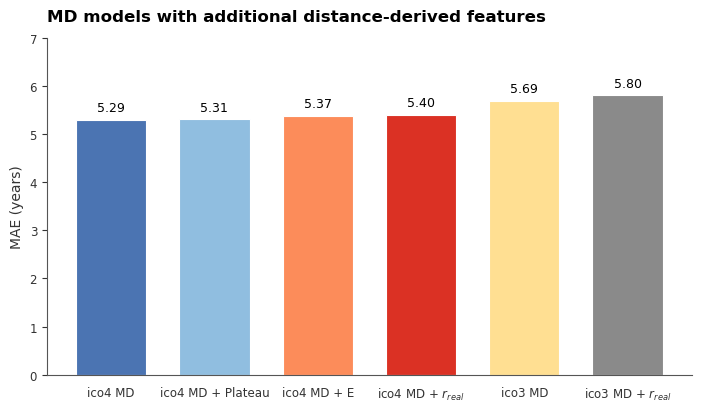

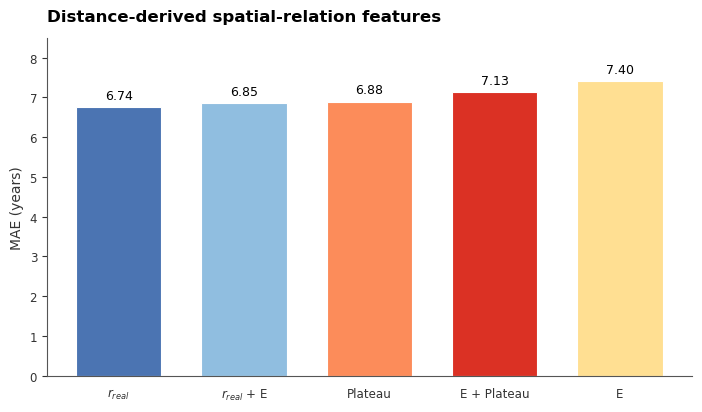

In [3]:
PALETTE = {
    'blue': '#4B74B2', 'light_blue': '#90BEE0', 'orange': '#FC8C5A',
    'red': '#DB3124', 'pale_yellow': '#FFDF92', 'gray': '#8A8A8A',
}
BAR_COLORS = [PALETTE[k] for k in ('blue', 'light_blue', 'orange', 'red', 'pale_yellow', 'gray')]

def plot_mae_bars(frame, title, stem):
    frame = frame.sort_values('MAE', kind='stable').reset_index(drop=True)
    if not frame['MAE'].is_monotonic_increasing:
        raise RuntimeError('Bars are not ordered from lower to higher MAE')
    x = np.arange(len(frame))
    colors = BAR_COLORS[:len(frame)]
    fig, ax = plt.subplots(figsize=(7.09, 4.2))
    bars = ax.bar(x, frame['MAE'], width=0.68, color=colors, edgecolor='white', linewidth=0.8)
    ax.set_xticks(x, frame['label'])
    ax.set_ylabel('MAE (years)')
    ax.set_title(title, loc='left', fontweight='bold', pad=12)
    ax.set_ylim(0, np.ceil((frame['MAE'].max() + 0.7) * 2) / 2)
    ax.grid(False)
    ax.tick_params(axis='x', length=0, pad=8)
    ax.bar_label(bars, labels=[f'{value:.2f}' for value in frame['MAE']], padding=4, fontsize=9)
    fig.tight_layout()
    for suffix in ('png', 'pdf', 'svg'):
        fig.savefig(OUTPUT_DIR / f'{stem}.{suffix}', bbox_inches='tight', facecolor='white')
    frame.to_csv(OUTPUT_DIR / f'{stem}_data.csv', index=False)
    plt.show()
    return fig

fig_md = plot_mae_bars(
    md_plot,
    'MD models with additional distance-derived features',
    'MD_plus_features_MAE',
)
fig_relation = plot_mae_bars(
    relation_plot,
    'Distance-derived spatial-relation features',
    'relation_features_MAE',
)

In [4]:
expected = [
    OUTPUT_DIR / f'{stem}.{suffix}'
    for stem in ('MD_plus_features_MAE', 'relation_features_MAE')
    for suffix in ('png', 'pdf', 'svg')
] + [
    OUTPUT_DIR / 'MD_plus_features_MAE_data.csv',
    OUTPUT_DIR / 'relation_features_MAE_data.csv',
]
missing = [str(path) for path in expected if not path.is_file()]
if missing:
    raise RuntimeError('Missing expected outputs:\n' + '\n'.join(missing))
print('QC passed: both panels are sorted by ascending MAE and all PNG/PDF/SVG/CSV outputs exist.')

QC passed: both panels are sorted by ascending MAE and all PNG/PDF/SVG/CSV outputs exist.
